# Plantilla de algoritmo. Parte 3 (Problema del Viajante)

**Cómo usarla:** copia este archivo como `parte3/<algoritmo>_<tunombre>.ipynb` (por ejemplo, `parte3/fuerza_bruta_pablo.ipynb`) y trabaja solo **debajo de la línea ✂️**. Lo de arriba (preparación) es el mismo código de la Parte 2 del trabajo y sirve para cargar las versiones del grafo: **no lo modifiques**. La guía completa está en `CONTRIBUTING.md`.

> ⚙️ El notebook se ejecuta desde su carpeta (`parte3/`): la primera celda sube a la raíz del proyecto para que las rutas (`data/...`) funcionen.

In [1]:
# Sube a la raíz del proyecto para que las rutas (data/ciudades.csv, data/versiones/...) funcionen
import os
from pathlib import Path
if Path.cwd().name == "parte3":
    os.chdir("..")

In [2]:
# Librerías que se usan en todo el notebook
import csv                       # leer y escribir tablas en formato CSV
import itertools                 # recorrer todas las combinaciones de parámetros
import unicodedata               # quitar acentos de los nombres (Cataluña -> cataluna)
from pathlib import Path         # rutas de archivos

import networkx as nx            # crear y analizar grafos (la misma librería de las prácticas)
import numpy as np               # tablas de números (las tablas de distancias)
from scipy.sparse import csr_matrix                 # matriz del grafo para el algoritmo de Dijkstra
from scipy.sparse.csgraph import dijkstra           # caminos mínimos desde varios orígenes
from scipy.spatial import cKDTree                   # buscar rápido el nodo más cercano a un punto

from tsp_utils import dibujar_red  # función de dibujo de la red de carreteras, comentada en tsp_utils.py

In [3]:
# ── Parámetros de las versiones (editables) ──
X_KM  = 10             # una ciudad a más de X_KM km de la red se deja fuera de la versión
N_MIN = 4              # mínimo de ciudades para una versión por comunidad autónoma
RECALCULAR = False     # True: vuelve a calcular las 16 tablas (necesita el grafo G de la Parte 1)
CARPETA = Path("data/versiones")     # aquí se guardan las tablas ya calculadas

# Qué tipos de vía (`highway`) puede usar cada versión de carreteras
CARRETERAS = {
    "completo":             ["motorway", "motorway_link", "trunk", "trunk_link",
                             "primary", "primary_link", "secondary", "secondary_link"],
    "autovias_principales": ["motorway", "motorway_link", "trunk", "trunk_link",
                             "primary", "primary_link"],
    "solo_autovias":        ["motorway", "motorway_link"],
    "sin_autovias":         ["trunk", "trunk_link", "primary", "primary_link",
                             "secondary", "secondary_link"],
}
PESOS = {"km": ("length", 1000), "tiempo": ("travel_time", 1)}   # peso -> (atributo de la arista, divisor)
CONJUNTOS = ["capitales", "capitales_y_100k"]                    # qué ciudades se visitan
GENERALES = ["multigrafo_dirigido", "grafo_dirigido",
             "multigrafo_no_dirigido", "grafo_simple_no_dirigido"]

In [4]:
# Lee la lista de ciudades (nombre, comunidad, si es capital de provincia, coordenadas...)
with open("data/ciudades.csv", encoding="utf-8") as f:
    CIUDADES = list(csv.DictReader(f))
for c in CIUDADES:
    c["lat"], c["lon"] = float(c["lat"]), float(c["lon"])
    c["capital"] = c["capital_provincia"] == "True"

def slug(texto):
    # "Castilla y León" -> "castilla_y_leon" (sin acentos ni espacios, para usarlo como nombre)
    sin_acentos = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sin_acentos.lower().replace(" ", "_").replace("-", "_")

AMBITOS = ["espana"] + sorted({slug(c["comunidad"]) for c in CIUDADES})

def ciudades_de(nodos, ambito):
    # Nombres de las ciudades de un conjunto: nodos = "capitales" o "capitales_y_100k";
    # ambito = "espana" o una comunidad (p. ej. "galicia")
    return [c["nombre"] for c in CIUDADES
            if (c["capital"] or nodos == "capitales_y_100k")
            and (ambito == "espana" or slug(c["comunidad"]) == ambito)]

print(f"{len(CIUDADES)} ciudades | {len(ciudades_de('capitales', 'espana'))} capitales | ámbitos: {len(AMBITOS) - 1} comunidades")
print("Capitales de Galicia:", ciudades_de("capitales", "galicia"))

75 ciudades | 47 capitales | ámbitos: 15 comunidades
Capitales de Galicia: ['A Coruña', 'Ourense', 'Lugo', 'Pontevedra']


In [5]:
def nombre_tabla(aristas, peso, dirigido):
    return CARPETA / f"{aristas}__{peso}__{'dirigido' if dirigido else 'no_dirigido'}.csv"

def guardar_tabla(D, nombres, ruta):
    with open(ruta, "w", encoding="utf-8") as f:
        np.savetxt(f, D, delimiter=",", header=",".join(nombres), comments="", fmt="%.3f")

def leer_tabla(aristas, peso, dirigido):
    ruta = nombre_tabla(aristas, peso, dirigido)
    with open(ruta, encoding="utf-8") as f:
        nombres = f.readline().strip().split(",")        # primera fila: nombres de las ciudades
    return np.loadtxt(ruta, delimiter=",", skiprows=1, encoding="utf-8"), nombres

def escribir_csv(ruta, filas, campos):
    with open(ruta, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=campos)
        w.writeheader()
        w.writerows(filas)

In [6]:
UNIDAD = {"km": "km", "tiempo": "segundos"}

def cargar_version(aristas, nodos, ambito, peso, general):
    # aristas: "completo" | "autovias_principales" | "solo_autovias" | "sin_autovias"
    # nodos:   "capitales" | "capitales_y_100k"       ambito: "espana" | "galicia" | "andalucia" ...
    # peso:    "km" | "tiempo"                        general: uno de GENERALES
    # (multigrafo y grafo simple dan el mismo grafo de ciudades: no hay aristas repetidas)
    dirigido = "no_dirigido" not in general
    D, nombres = leer_tabla(aristas, peso, dirigido)
    elegidas = [c for c in ciudades_de(nodos, ambito) if c in nombres]    # sin las que quedaron fuera
    if ambito != "espana" and len(elegidas) < N_MIN:
        raise ValueError(f"Solo hay {len(elegidas)} ciudades (mínimo {N_MIN}) en {ambito}")
    K = nx.DiGraph() if dirigido else nx.Graph()
    for c in CIUDADES:
        if c["nombre"] in elegidas:
            K.add_node(c["nombre"], lat=c["lat"], lon=c["lon"])
    for p, a in enumerate(elegidas):
        for q, b in enumerate(elegidas):
            if p != q and (dirigido or p < q):                            # no dirigido: una arista por par
                K.add_edge(a, b, peso=float(D[nombres.index(a), nombres.index(b)]))
    K.graph.update(aristas=aristas, nodos=nodos, ambito=ambito, peso=peso,
                   unidad=UNIDAD[peso], general=general,
                   fuera=[c for c in ciudades_de(nodos, ambito) if c not in nombres])
    return K

In [7]:
# [AYUDA COMPARTIDA] Funciones comunes a todos los algoritmos
import time
import tracemalloc

def coste_ruta(K, ruta):
    # Coste total del ciclo: suma de las distancias entre ciudades consecutivas y de la última a la primera
    return sum(K[ruta[i]][ruta[(i + 1) % len(ruta)]]["peso"] for i in range(len(ruta)))

def validar_ruta(K, ruta):
    # Comprueba que la ruta visita cada ciudad de K exactamente una vez
    assert len(ruta) == K.number_of_nodes() and set(ruta) == set(K.nodes), "la ruta no visita cada ciudad una vez"

def medir(algoritmo, K, memoria=False, **opciones):
    # Ejecuta algoritmo(K, **opciones), comprueba el resultado y devuelve cuánto ha tardado
    # (con memoria=True mide también el pico de memoria en una segunda ejecución, porque medirla ralentiza)
    t0 = time.perf_counter()
    ruta, coste = algoritmo(K, **opciones)
    segundos = time.perf_counter() - t0
    validar_ruta(K, ruta)
    assert abs(coste - coste_ruta(K, ruta)) < 1e-6 * max(1.0, abs(coste)), "el coste devuelto no coincide con el de la ruta"
    resultado = {"algoritmo": algoritmo.__name__, "ciudades": K.number_of_nodes(), "coste": round(coste, 3),
                 "unidad": K.graph.get("unidad"), "segundos": round(segundos, 4)}
    if memoria:
        tracemalloc.start()
        algoritmo(K, **opciones)
        _, pico = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        resultado["memoria_mb"] = round(pico / 1e6, 2)
    return resultado

---
### ✂️ A PARTIR DE AQUÍ SE INTEGRA EN EL TRABAJO

Todo lo que escribas **debajo de esta línea** pasará al notebook principal (`trabajo_tsp.ipynb`, Parte 3). No modifiques esta celda.

### Algoritmo genético

**🗂️ FICHA**

| | |
|---|---|
| **Autor** | Raimundo |
| **Función** | `genetico(K, inicio=None, poblacion=150, generaciones=500, ...)` |
| **Tipo** | Metaheurística |
| **Determinista** | No (reproducible fijando la semilla) |
| **Garantía de calidad** | Ninguna |
| **Distancias simétricas** | No la necesita |
| **Complejidad en tiempo** | O(G·P·n·q) |
| **Complejidad en memoria** | O(P·n) |
| **Límite práctico** | Todas |
| **Uso de IA** | Texto y código elaborados con ayuda de Claude (Anthropic); probados y revisados por el autor. |

<div style="border-left:5px solid #4C72B0;color:#000;background:#EEF2FA;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📚 TEORÍA**

Es una **metaheurística** inspirada en la evolución de las especies: en lugar de construir una ruta, se mantiene una **población de rutas** que va "evolucionando" durante muchas **generaciones**. Las rutas más cortas tienen más probabilidades de reproducirse, sus "hijos" combinan características de los padres y, de vez en cuando, sufren pequeñas **mutaciones**. Con el tiempo la población converge hacia rutas cada vez mejores.

**Elementos del algoritmo.**

- **Individuo:** una ruta, es decir, una **permutación** de las ciudades (la de inicio queda fija en primer lugar). Es siempre válida: visita cada ciudad una vez.
- **Aptitud (*fitness*):** el coste del ciclo; cuanto menor, mejor. Se calcula con `numpy` para toda la población a la vez.
- **Selección por torneo:** para elegir cada padre se toman `torneo` individuos al azar y gana el de menor coste. Es sencilla y deja una pequeña ventaja a los mejores sin eliminar a los demás (mantiene la diversidad).
- **Cruce por orden (OX):** el hijo hereda de un padre **un tramo seguido** de la ruta, y el resto de ciudades se colocan **en el orden en que aparecen en el otro padre**. Así el hijo nunca repite ni se deja ninguna ciudad.
- **Mutación guiada:** con probabilidad `prob_mutacion`, se prueban `intentos` **inversiones de un tramo** al azar (el movimiento del 2-opt) y el individuo se queda con la mejor *solo si mejora* su coste. Es un pequeño empujón de búsqueda local que acelera mucho la convergencia (un genético "puro" necesitaría muchísimas más generaciones, ver los resultados).
- **Elitismo:** los `elite` mejores individuos pasan intactos a la siguiente generación, para no perder nunca la mejor ruta encontrada.
- **Parada:** tras `generaciones` generaciones, o antes si el mejor coste lleva `paciencia` generaciones sin mejorar.

**Pseudocódigo.**

<pre style="background:#fff;border:1px solid #ccd;padding:10px 14px;border-radius:4px;font-size:13px;">
GENÉTICO(K, inicio, población, generaciones, ...):
    población ← `población` permutaciones aleatorias de las ciudades (menos inicio)
    mejor ← la de menor coste
    repetir hasta `generaciones` o hasta `paciencia` generaciones sin mejorar:
        padres ← para cada plaza, el mejor de `torneo` individuos elegidos al azar
        nueva ← los `elite` mejores de la población actual
        mientras nueva no esté completa:
            hijo ← CRUCE_OX(un padre, el siguiente)
            con probabilidad prob_mutacion:  MUTACIÓN_GUIADA(hijo)
            añadir hijo a nueva
        población ← nueva ;  actualizar mejor
    devolver (inicio + mejor, coste de mejor)
</pre>

**Complejidad.** **Tiempo: O(G · P · n · q)**, con `G` generaciones, `P` individuos, `n` ciudades y `q` intentos de mutación: en cada generación se cruzan y evalúan `P` rutas de longitud `n` (y la mutación prueba `q` variantes). Es **lineal en `n`** por generación, pero la calidad exige más generaciones y población al crecer `n`. **Memoria: O(P·n)**: solo la población y los hijos; el grafo en forma de matriz ocupa `O(n²)`.

**Propiedades.**

- **Tipo:** **metaheurística estocástica** (no es exacto).
- **¿Siempre encuentra el óptimo?** **No**, aunque con instancias pequeñas suele darlo, y con las grandes se acerca bastante (se mide abajo).
- **¿Determinista?** **No por naturaleza** —usa azar—, pero se hace **reproducible fijando la semilla** (`semilla=42`): con la misma semilla devuelve siempre la misma ruta. Con semillas distintas los resultados varían, por eso se mide sobre varias.
- **¿Garantía de calidad?** **Ninguna.** Es imposible saber, sin conocer el óptimo, cuánto se ha quedado lejos.
- **¿Necesita simetría?** **No**: solo consulta el coste de cada arista en su sentido, sirve para `nx.DiGraph` y `nx.Graph`.
- **¿Hasta cuántas ciudades?** **Todas.** No tiene un límite duro; la calidad baja y el tiempo sube al crecer `n`, y hay que ajustar los parámetros (población, generaciones, mutación).
- **Parámetros:** `poblacion`, `generaciones`, `prob_mutacion`, `torneo`, `elite`, `intentos`, `paciencia` y `semilla`. Encontrar buenos valores es parte del trabajo; abajo se estudia el efecto de la población.

</div>

**💻 CÓDIGO**

Dentro de la función, `costes` evalúa de golpe a toda la población, `cruce_ox` y `mutar` son los operadores genéticos y el bucle principal repite selección, cruce, mutación y reemplazo. Toda la aleatoriedad sale de un único generador (`np.random.default_rng(semilla)`), por lo que fijar la semilla hace reproducible la ejecución. Si se pasa una lista en `historial`, se guarda en ella el mejor coste de cada generación (sirve para dibujar la convergencia).

In [8]:
def genetico(K, inicio=None, poblacion=150, generaciones=500, prob_mutacion=0.5,
             torneo=3, elite=2, intentos=10, paciencia=150, semilla=42, historial=None):
    # Algoritmo genético para el problema del viajante. Contrato: K es el grafo de ciudades (completo,
    # K[a][b]["peso"]) y devuelve (ruta, coste), con la ruta completa (cada ciudad una vez, el viajante
    # vuelve después a la primera) y el coste del ciclo incluida la vuelta. No asume simetría. Es una
    # metaheurística: no garantiza el óptimo, pero con la misma `semilla` repite siempre el resultado.
    # Si se pasa una lista en `historial`, se le añade el mejor coste de cada generación.

    ciudades = list(K.nodes)
    n = len(ciudades)

    # Casos triviales y comprobaciones
    if n == 0:
        return [], 0.0
    if inicio is None:
        inicio = ciudades[0]
    elif inicio not in K:
        raise KeyError(f"La ciudad de inicio {inicio!r} no está en el grafo")
    orden = [inicio] + [c for c in ciudades if c != inicio]   # índice 0 = inicio (siempre sale de ahí)
    # Con 3 ciudades o menos solo hay 2 rutas posibles: se prueban todas
    if n <= 3:
        rutas = [[inicio] + [orden[i] for i in p] for p in itertools.permutations(range(1, n))]
        coste_de = lambda r: sum(K[r[i]][r[(i + 1) % n]]["peso"] for i in range(n)) if n > 1 else 0.0
        mejor = min(rutas, key=coste_de)
        return mejor, float(coste_de(mejor))

    # Matriz de costes W[i][j] (rápida de consultar) y número de ciudades que se reordenan
    W = np.array([[0.0 if a == b else K[a][b]["peso"] for b in orden] for a in orden])
    m = n - 1

    rng = np.random.default_rng(semilla)                      # generador de azar con semilla fija

    def costes(pob):
        # Coste del ciclo de cada individuo (cada fila es el orden de visita de las ciudades 1..n-1,
        # con el inicio 0 delante y la vuelta al final). Todo a la vez, sin bucles.
        return W[0, pob[:, 0]] + W[pob[:, :-1], pob[:, 1:]].sum(axis=1) + W[pob[:, -1], 0]

    def cruce_ox(p1, p2):
        # Cruce por orden (OX): el hijo hereda de p1 un tramo seguido y el resto de ciudades
        # en el orden en que aparecen en p2. Así el hijo siempre es una ruta válida.
        a, b = np.sort(rng.choice(m + 1, size=2, replace=False))
        tramo = p1[a:b]
        resto = np.roll(p2, -b)
        resto = resto[~np.isin(resto, tramo)]
        hijo = np.empty(m, dtype=p1.dtype)
        hijo[a:b] = tramo
        hijo[np.r_[b:m, 0:a]] = resto
        return hijo

    def mutar(ind):
        # Mutación guiada: se proponen `intentos` inversiones de un tramo al azar (como movimientos
        # 2-opt) y el individuo se queda con la mejor, solo si es mejor que la ruta que ya tenía
        ini = rng.integers(0, m - 1, size=intentos)
        fin = ini + 1 + rng.integers(0, m - 1, size=intentos) % (m - 1 - ini)
        candidatos = np.tile(ind, (intentos, 1))
        for k in range(intentos):
            candidatos[k, ini[k]:fin[k] + 1] = ind[ini[k]:fin[k] + 1][::-1]
        cc = costes(candidatos)
        if cc.min() < costes(ind[None, :])[0]:
            ind[:] = candidatos[cc.argmin()]

    # Población inicial: `poblacion` rutas aleatorias
    pob = np.array([rng.permutation(m) + 1 for _ in range(poblacion)])
    c = costes(pob)
    mejor_coste, mejor = c.min(), pob[c.argmin()].copy()
    sin_mejora = 0

    for g in range(generaciones):
        # Selección por torneo: cada padre es el mejor de `torneo` individuos elegidos al azar
        candidatos = rng.integers(0, poblacion, size=(poblacion, torneo))
        padres = pob[candidatos[np.arange(poblacion), c[candidatos].argmin(axis=1)]]

        # Nueva generación: los `elite` mejores pasan tal cual; el resto son hijos de padres consecutivos
        nueva = [pob[k].copy() for k in np.argsort(c)[:elite]]
        while len(nueva) < poblacion:
            k = rng.integers(0, poblacion)
            hijo = cruce_ox(padres[k], padres[(k + 1) % poblacion])
            if rng.random() < prob_mutacion:
                mutar(hijo)
            nueva.append(hijo)
        pob = np.array(nueva)
        c = costes(pob)

        # Guardamos el mejor y paramos si lleva `paciencia` generaciones sin mejorar
        if c.min() < mejor_coste - 1e-9:
            mejor_coste, mejor, sin_mejora = c.min(), pob[c.argmin()].copy(), 0
        else:
            sin_mejora += 1
        if historial is not None:
            historial.append(float(mejor_coste))
        if sin_mejora >= paciencia:
            break

    ruta = [orden[0]] + [orden[i] for i in mejor]
    return ruta, float(mejor_coste)

**🧪 PRUEBAS**

**Prueba rápida.** Tres comprobaciones:

1. **Versión pequeña real:** las 6 ciudades de Galicia empezando en Vigo, con `validar_ruta` y `medir` (tiempo y memoria).
2. **Referencia exacta:** el mejor de los `6! = 720` ciclos posibles.
3. **Reproducibilidad:** dos ejecuciones con la misma semilla deben dar exactamente la misma ruta.

In [9]:
# ── 1. Versión pequeña real: Galicia (6 ciudades), empezando en Vigo ──
K = cargar_version(aristas="completo", nodos="capitales_y_100k", ambito="galicia", peso="km", general="grafo_dirigido")
ruta, coste = genetico(K, inicio="Vigo")
validar_ruta(K, ruta)                               # comprueba que la ruta visita cada ciudad una vez
print(" → ".join(ruta), f"| coste: {coste:.1f} {K.graph['unidad']}")
print(medir(genetico, K, memoria=True, inicio="Vigo"))

# ── 2. Referencia: el mejor de los 6! = 720 ciclos ──
optimo = min(coste_ruta(K, list(p)) for p in itertools.permutations(K.nodes))
print(f"\nóptimo de los 720 ciclos: {optimo:.3f} km | genético: {coste:.3f} km | diferencia: {coste - optimo:+.3f} km")

# ── 3. Reproducibilidad: misma semilla, misma ruta ──
print("misma semilla → misma ruta:", genetico(K, inicio="Vigo", semilla=7)[0] == genetico(K, inicio="Vigo", semilla=7)[0])

Vigo → Ourense → Lugo → A Coruña → Santiago de Compostela → Pontevedra | coste: 460.4 km


{'algoritmo': 'genetico', 'ciudades': 6, 'coste': 460.438, 'unidad': 'km', 'segundos': 2.7899, 'memoria_mb': 0.07}

óptimo de los 720 ciclos: 460.438 km | genético: 460.438 km | diferencia: +0.000 km


misma semilla → misma ruta: True


**Convergencia (47 capitales).** Se dibuja el mejor coste en cada generación. Al principio la población es aleatoria (rutas de decenas de miles de km) y baja muy deprisa; después se estabiliza. La línea horizontal es el **óptimo de esta versión (`completo`/`km`/dirigido): 5.917,562 km**, calculado con el algoritmo DFJ del notebook de Jiahao.

500 generaciones | coste final: 6042.7 km (+2.1 % sobre el óptimo)


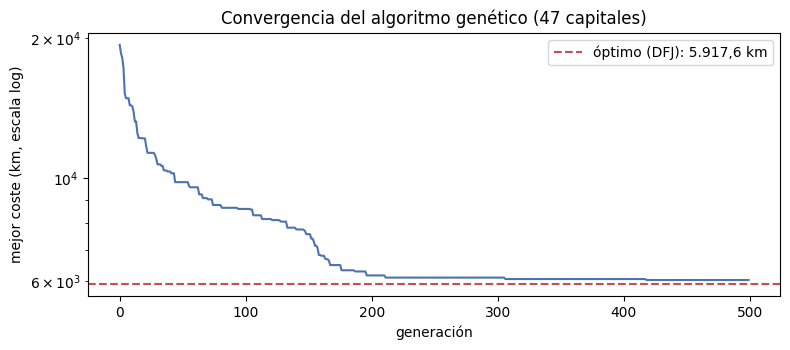

In [10]:
# ── Convergencia del genético sobre 47 capitales (dirigido, km) ──
import matplotlib.pyplot as plt
K47 = cargar_version(aristas="completo", nodos="capitales", ambito="espana", peso="km", general="grafo_dirigido")
OPTIMO_47 = 5917.562                                 # óptimo calculado con DFJ (notebook de Jiahao)
historial = []
ruta, coste = genetico(K47, historial=historial)
validar_ruta(K47, ruta)
print(f"{len(historial)} generaciones | coste final: {coste:.1f} km ({(coste - OPTIMO_47) / OPTIMO_47 * 100:+.1f} % sobre el óptimo)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(historial, color="#4C72B0")
ax.axhline(OPTIMO_47, color="#C44E52", linestyle="--", label="óptimo (DFJ): 5.917,6 km")
ax.set_yscale("log")
ax.set_xlabel("generación"); ax.set_ylabel("mejor coste (km, escala log)")
ax.set_title("Convergencia del algoritmo genético (47 capitales)")
ax.legend(); plt.tight_layout(); plt.show()

**Variabilidad con el azar (47 capitales).** Al ser estocástico, un solo resultado no basta: se ejecuta con 5 semillas distintas y se resume el mejor, el peor, la media y la desviación.

In [11]:
# ── 5 semillas distintas sobre 47 capitales ──
import time
resultados, tiempos = [], []
for semilla in (1, 2, 3, 4, 5):
    t0 = time.perf_counter()
    _, c = genetico(K47, semilla=semilla)
    tiempos.append(time.perf_counter() - t0)
    resultados.append(c)
    print(f"semilla {semilla}: {c:>8.1f} km ({(c - OPTIMO_47) / OPTIMO_47 * 100:>+5.1f} %) | {tiempos[-1]:.1f} s")
print(f"\nmejor {min(resultados):.1f} | peor {max(resultados):.1f} | media {np.mean(resultados):.1f} | desviación {np.std(resultados):.1f} km")
print(f"media sobre el óptimo: {(np.mean(resultados) - OPTIMO_47) / OPTIMO_47 * 100:+.1f} % | tiempo medio: {np.mean(tiempos):.1f} s")

semilla 1:   6048.6 km ( +2.2 %) | 5.5 s


semilla 2:   6240.1 km ( +5.4 %) | 9.4 s


semilla 3:   6117.6 km ( +3.4 %) | 8.3 s


semilla 4:   6233.1 km ( +5.3 %) | 6.4 s


semilla 5:   6058.2 km ( +2.4 %) | 6.6 s

mejor 6048.6 | peor 6240.1 | media 6139.5 | desviación 82.7 km
media sobre el óptimo: +3.8 % | tiempo medio: 7.2 s


**Efecto de los parámetros (47 capitales, semilla 42).** Se varía la **población** (20, 150, 400) y se compara con una **mutación mínima** (`intentos=1`: una sola inversión de prueba en lugar de 10), para ver cuánto aporta la mutación guiada.

In [12]:
# ── Efecto de la población y de la mutación guiada ──
print(f"{'configuración':>34} | {'coste (km)':>10} | {'sobre óptimo':>12} | {'tiempo':>7}")
for nombre, opciones in (("población 20", dict(poblacion=20)),
                         ("población 150 (por defecto)", dict()),
                         ("población 400", dict(poblacion=400)),
                         ("mutación mínima (intentos=1)", dict(intentos=1))):
    t0 = time.perf_counter()
    _, c = genetico(K47, **opciones)
    print(f"{nombre:>34} | {c:>10.1f} | {(c - OPTIMO_47) / OPTIMO_47 * 100:>+11.1f}% | {time.perf_counter() - t0:>6.1f}s")

                     configuración | coste (km) | sobre óptimo |  tiempo


                      población 20 |     6082.3 |        +2.8% |    0.8s


       población 150 (por defecto) |     6042.7 |        +2.1% |    9.4s


                     población 400 |     6261.0 |        +5.8% |   25.3s


      mutación mínima (intentos=1) |     6675.6 |       +12.8% |    6.1s


**Escalabilidad.** Se ejecuta sobre las versiones `completo` de España con 47 y 75 ciudades, dirigidas y no dirigidas (semilla `42`).

In [13]:
# ── Escalabilidad: 47 y 75 ciudades, dirigido y no dirigido ──
print(f"{'ciudades':>8} | {'general':>24} | {'coste (km)':>10} | {'tiempo':>8} | {'memoria (MB)':>12}")
for nodos in ("capitales", "capitales_y_100k"):
    for general in ("grafo_dirigido", "grafo_simple_no_dirigido"):
        Kv = cargar_version(aristas="completo", nodos=nodos, ambito="espana", peso="km", general=general)
        r = medir(genetico, Kv, memoria=True)
        print(f"{r['ciudades']:>8} | {general:>24} | {r['coste']:>10.1f} | {r['segundos']:>7.1f}s | {r['memoria_mb']:>12.2f}")

ciudades |                  general | coste (km) |   tiempo | memoria (MB)


      47 |           grafo_dirigido |     6042.7 |     9.4s |         0.38


      47 | grafo_simple_no_dirigido |     5940.2 |     8.9s |         0.38


      75 |           grafo_dirigido |     6424.3 |    10.7s |         0.56


      75 | grafo_simple_no_dirigido |     6402.9 |     9.6s |         0.56


<div style="border-left:5px solid #55A868;color:#000;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESULTADOS**

**Prueba rápida (Galicia, 6 ciudades, desde Vigo).** Ruta devuelta: **Vigo → Ourense → Lugo → A Coruña → Santiago de Compostela → Pontevedra → Vigo = 460,4 km**, el **óptimo** (fuerza bruta: 460,438 km). Con la misma semilla repite exactamente la misma ruta.

**Convergencia** (47 capitales, `completo`/`km`/dirigido, semilla 42): en 500 generaciones llega a **6.042,7 km, un +2,1 % sobre el óptimo** (5.917,6 km según DFJ). La curva cae en picado en las primeras decenas de generaciones (de rutas aleatorias de decenas de miles de km) y después mejora lentamente.

**Variabilidad con el azar** (5 semillas, 47 capitales):

| Semilla | Coste | Sobre el óptimo |
|---:|---:|---:|
| 1 | 6.048,6 km | +2,2 % |
| 2 | 6.240,1 km | +5,4 % |
| 3 | 6.117,6 km | +3,4 % |
| 4 | 6.233,1 km | +5,3 % |
| 5 | 6.058,2 km | +2,4 % |

Mejor 6.048,6 km, peor 6.240,1 km, **media 6.139,5 km (+3,8 %)**, desviación 82,7 km. Un solo resultado no basta para describir el algoritmo: entre la mejor y la peor semilla hay más de 3 puntos de diferencia.

**Efecto de los parámetros** (47 capitales, semilla 42, 500 generaciones máx.): población 20 → +2,8 % (0,8 s); **población 150 → +2,1 % (9,4 s)**; población 400 → +5,8 % (25,4 s). Más población **no mejora** si el número de generaciones es el mismo (cada generación avanza menos). La **mutación guiada** es decisiva: con una sola inversión de prueba (`intentos=1`) el resultado empeora a +12,8 %; en las pruebas previas con una mutación aleatoria simple, sin comprobar si mejora, el error estuvo entre +19 % y +37 %.

**Escalabilidad** (`completo`/`km`, semilla 42): 47 ciudades dirigido 6.042,7 km (9,5 s) y no dirigido 5.940,2 km (8,8 s); 75 ciudades dirigido 6.424,3 km (9,7 s) y no dirigido 6.402,9 km (9,4 s). El tiempo apenas cambia con `n` (crece linealmente por generación, con el mismo número de generaciones) y la memoria es mínima (< 1 MB). **Comparación:** en las 47 capitales dirigidas queda mejor que el 2-opt desde el vecino más cercano (+6,9 %), pero **tarda ~9 s frente a milisegundos** y no da garantías; DFJ (Jiahao) da el óptimo en unos 2 s con estos tamaños.

</div>

---